In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
from PyLTSpice.editor.spice_editor import SpiceEditor

import ltspice_automation.sim as lt
import ltspice_automation.raw as rw
from ltspice_automation.paths import models_dir

BASE_DIR = models_dir("basic-components")

ASC: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\models\basic-components\ohm_law\ohm.asc
RAW: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\models\basic-components\ohm_law\ohm.raw
Traces: ['time', 'V(n001)', 'V(n002)', 'I(R3)', 'I(R1)', 'I(R2)', 'I(V1)']
CSV saved to: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\models\basic-components\ohm_law\ohm.csv


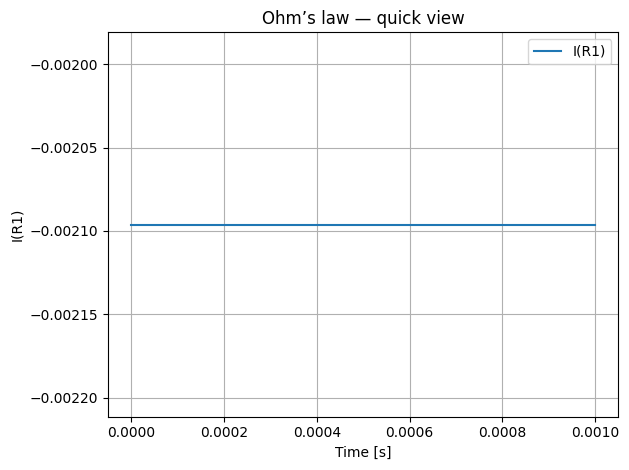

In [ ]:

asc_file = (BASE_DIR / "ohm_law" / "ohm.asc").resolve()


print(f"ASC: {asc_file}")
raw_path = lt.run_sim(asc_file, analysis_card=".tran 1m", wait_seconds=60)
print(f"RAW: {raw_path}")

print("Traces:", rw.list_traces(raw_path))

rr = rw.read_raw(raw_path)
df = rw.raw_to_dataframe(rr)
csv_path = rw.save_csv(df, raw_path.with_suffix(".csv"))
print(f"CSV saved to: {csv_path}")

rw.quick_plot(df, title="Ohm’s law — quick view")
lt.clear_sim_outputs(asc_file)

In [ ]:
def diode_circuit(asc_file: str | Path, R: str) -> pd.DataFrame:
    asc_path = Path(asc_file)
    spice = SpiceEditor(str(asc_path))
    spice.add_instructions(".dc V1 0 12 0.1")
    spice.set_component_value("R1", R)

    raw_path = lt.run_sim(asc_path=asc_path, spice=spice,analysis_card=".dc V1 0 12 0.1", output_dir=asc_path.parent, run_name=asc_path.stem, wait_seconds=50)
    rr = rw.read_raw(raw_path)
    df = rw.raw_to_dataframe(rr)

    return df

In [4]:
def plot_diode_characteristic(i,v, name, title, x, up="U_p"):

    fig,ax = plt.subplots(figsize=(8, 6))
    ax.plot(v, i, label="1N914 diode characteristics", color='blue')
    ax.set_xlabel("voltage [V]")
    ax.set_ylabel("current [mA]")
    ax.axvline(x = x, color = 'r', label = f'${up} = {np.abs(x)}$ [V]', linestyle='--')
    ax.legend()
    ax.grid(True)
    
    plt.show()
    fig.savefig(f"{name}_graphs")

In [5]:
name ="rectifier_diode"
asc_file = BASE_DIR / f"{name}\\{name}.asc"
R = "5078.3"

df = diode_circuit(asc_file, R)

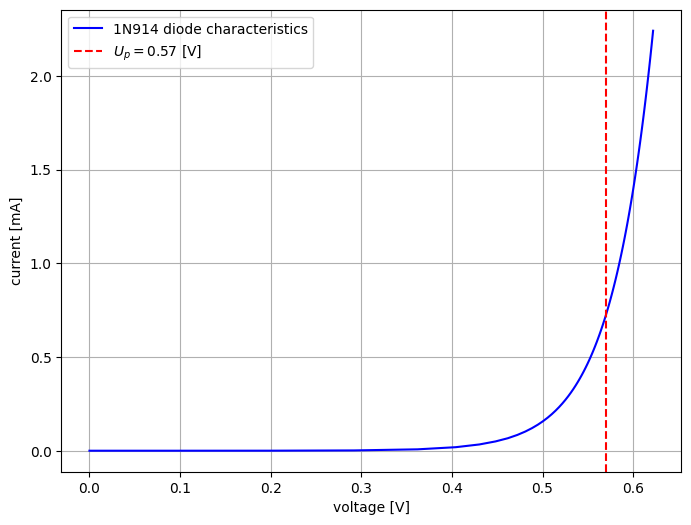

In [ ]:
v = df["V(n002)"]
i = df["I(D1)"] * 1000

plot_diode_characteristic(i, v,  name, "rectifier_diode", 0.57)
lt.clear_sim_outputs(asc_file)